In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import patches as mpatches
from hyperparameter_search import HYPERPARAMETER_GROUPS
from utils import AUX_HEAD_KEYS
from tqdm import tqdm
import math
import numpy as np
from scipy import stats
from scipy.stats import false_discovery_control, ttest_ind

/Users/jacquesamsel/.pyenv/versions/skripsie2/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
data = pd.read_csv("results/aux_head_regression_scores.csv")
data["run_number"] = data["model_name"].str[-1].astype(int)
data["model_name"] = data["model_name"].str[:-3]
data["aux_weight"] = data["model_name"].str.extract(r"_w([\d\.]+)$").astype(float)
data["model_name"] = data["model_name"].str.replace(r"_w[\d\.]+$", "", regex=True)
data["readable_name"] = data["model_name"] + data["aux_weight"].map(lambda x: f" Weight={x}" if x > 0 else "")
data

,model_name,target,iteration,r2_score,mae,target_stddev,run_number,aux_weight,readable_name
0,angular_velocity_y,velocity_forward,0,0.480349,0.183559,0.592117,2,0.1,angular_velocity_y Weight=0.1
1,angular_velocity_y,velocity_lateral,0,0.864162,0.018511,0.066221,2,0.1,angular_velocity_y Weight=0.1
2,angular_velocity_y,track_curvature_0_50,0,0.265886,0.276100,0.466201,2,0.1,angular_velocity_y Weight=0.1
3,angular_velocity_y,track_curvature_1_00,0,0.199226,0.290405,0.462444,2,0.1,angular_velocity_y Weight=0.1
4,angular_velocity_y,track_curvature_1_50,0,0.046198,0.322317,0.468267,2,0.1,angular_velocity_y Weight=0.1
...,...,...,...,...,...,...,...,...,...
60097,baseline,wheel_slip_forward_front_right,600,0.079978,0.047037,0.099006,6,0.0,baseline
60098,baseline,wheel_slip_lateral_front_right,600,0.839062,0.004491,0.017453,6,0.0,baseline
60099,baseline,wheel_slip_forward_back_right,600,0.089675,0.047405,0.100029,6,0.0,baseline
60100,baseline,wheel_slip_lateral_back_right,600,0.543212,0.002068,0.005463,6,0.0,baseline


In [20]:
data.duplicated(subset=["model_name", "aux_weight", "run_number", "target"]).sum()

np.int64(57240)

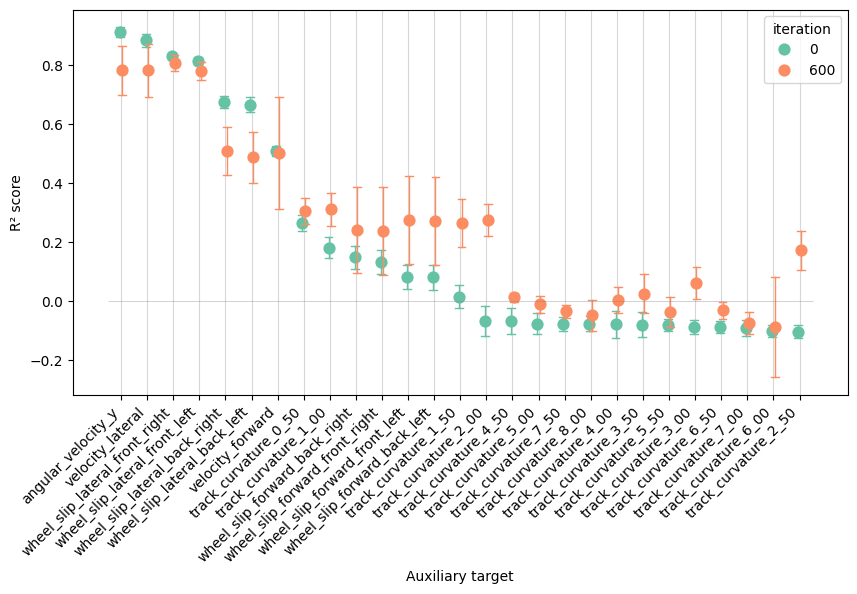

In [112]:
raw = data[(data["model_name"] == "baseline") & (data["iteration"].isin([0, 600]))]

plt.figure(figsize=(10, 5))
sns.pointplot(
    data=raw, x="target", y="r2_score", hue="iteration",
    order=(raw[raw["iteration"] == 0]
         .groupby("target")["r2_score"].mean()
         .sort_values(ascending=False)   # highest first; drop for lowest first
         .index.tolist()),
    errorbar="sd",
    dodge=0.1,
    linestyle="none",
    palette="Set2",
    capsize=0.3,
    err_kws={"linewidth": 1}
).set(xlabel="Auxiliary target", ylabel="R² score")
plt.grid(axis="x", alpha=0.5)
plt.xticks(rotation=45, ha="right")
plt.hlines(y=0, xmin=-0.5, xmax=len(AUX_HEAD_KEYS)-0.5, colors="gray" ,alpha=0.5, lw=0.5)

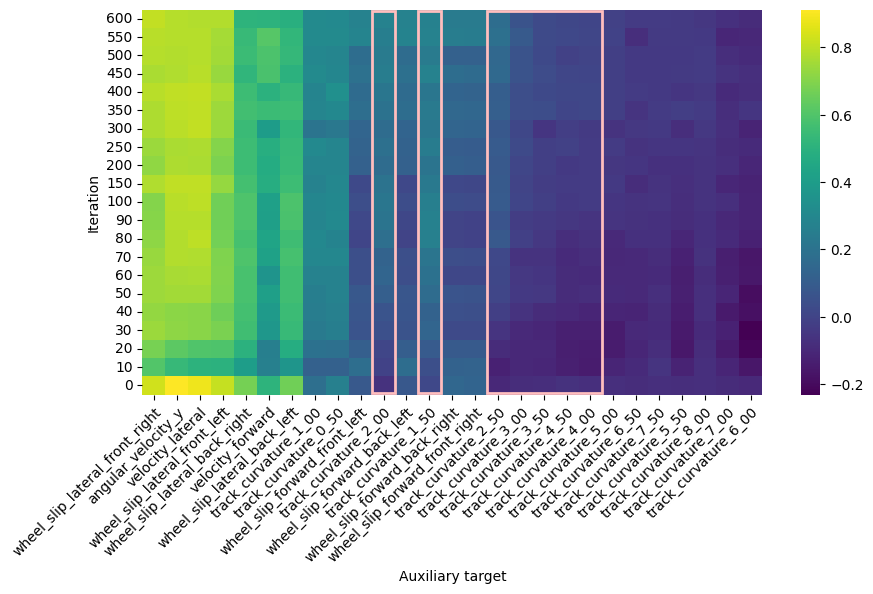

In [136]:
to_show = data[data["model_name"] == "baseline"].pivot_table(index="iteration", columns="target", values="r2_score")[::-1]
to_show = to_show[to_show.columns[to_show.loc[600].argsort()][::-1]]
plt.figure(figsize=(10, 5))
ax = sns.heatmap(to_show, cmap="viridis")
ax.set(xlabel="Auxiliary target", ylabel="Iteration")

rect1 = mpatches.Rectangle((15, 0.1), 5, 20.8,
                          linewidth=2, edgecolor="#ffbebe", facecolor='none')
rect2 = mpatches.Rectangle((10, 0.1), 1, 20.8,
                          linewidth=2, edgecolor='#ffbebe', facecolor='none')
rect3 = mpatches.Rectangle((12, 0.1), 1, 20.8,
                          linewidth=2, edgecolor='#ffbebe', facecolor='none')
ax.add_patch(rect1)
ax.add_patch(rect2)
ax.add_patch(rect3)

plt.xticks(rotation=45, ha="right", rotation_mode="anchor")
plt.savefig("results/figures/probe_heatmap.pdf")

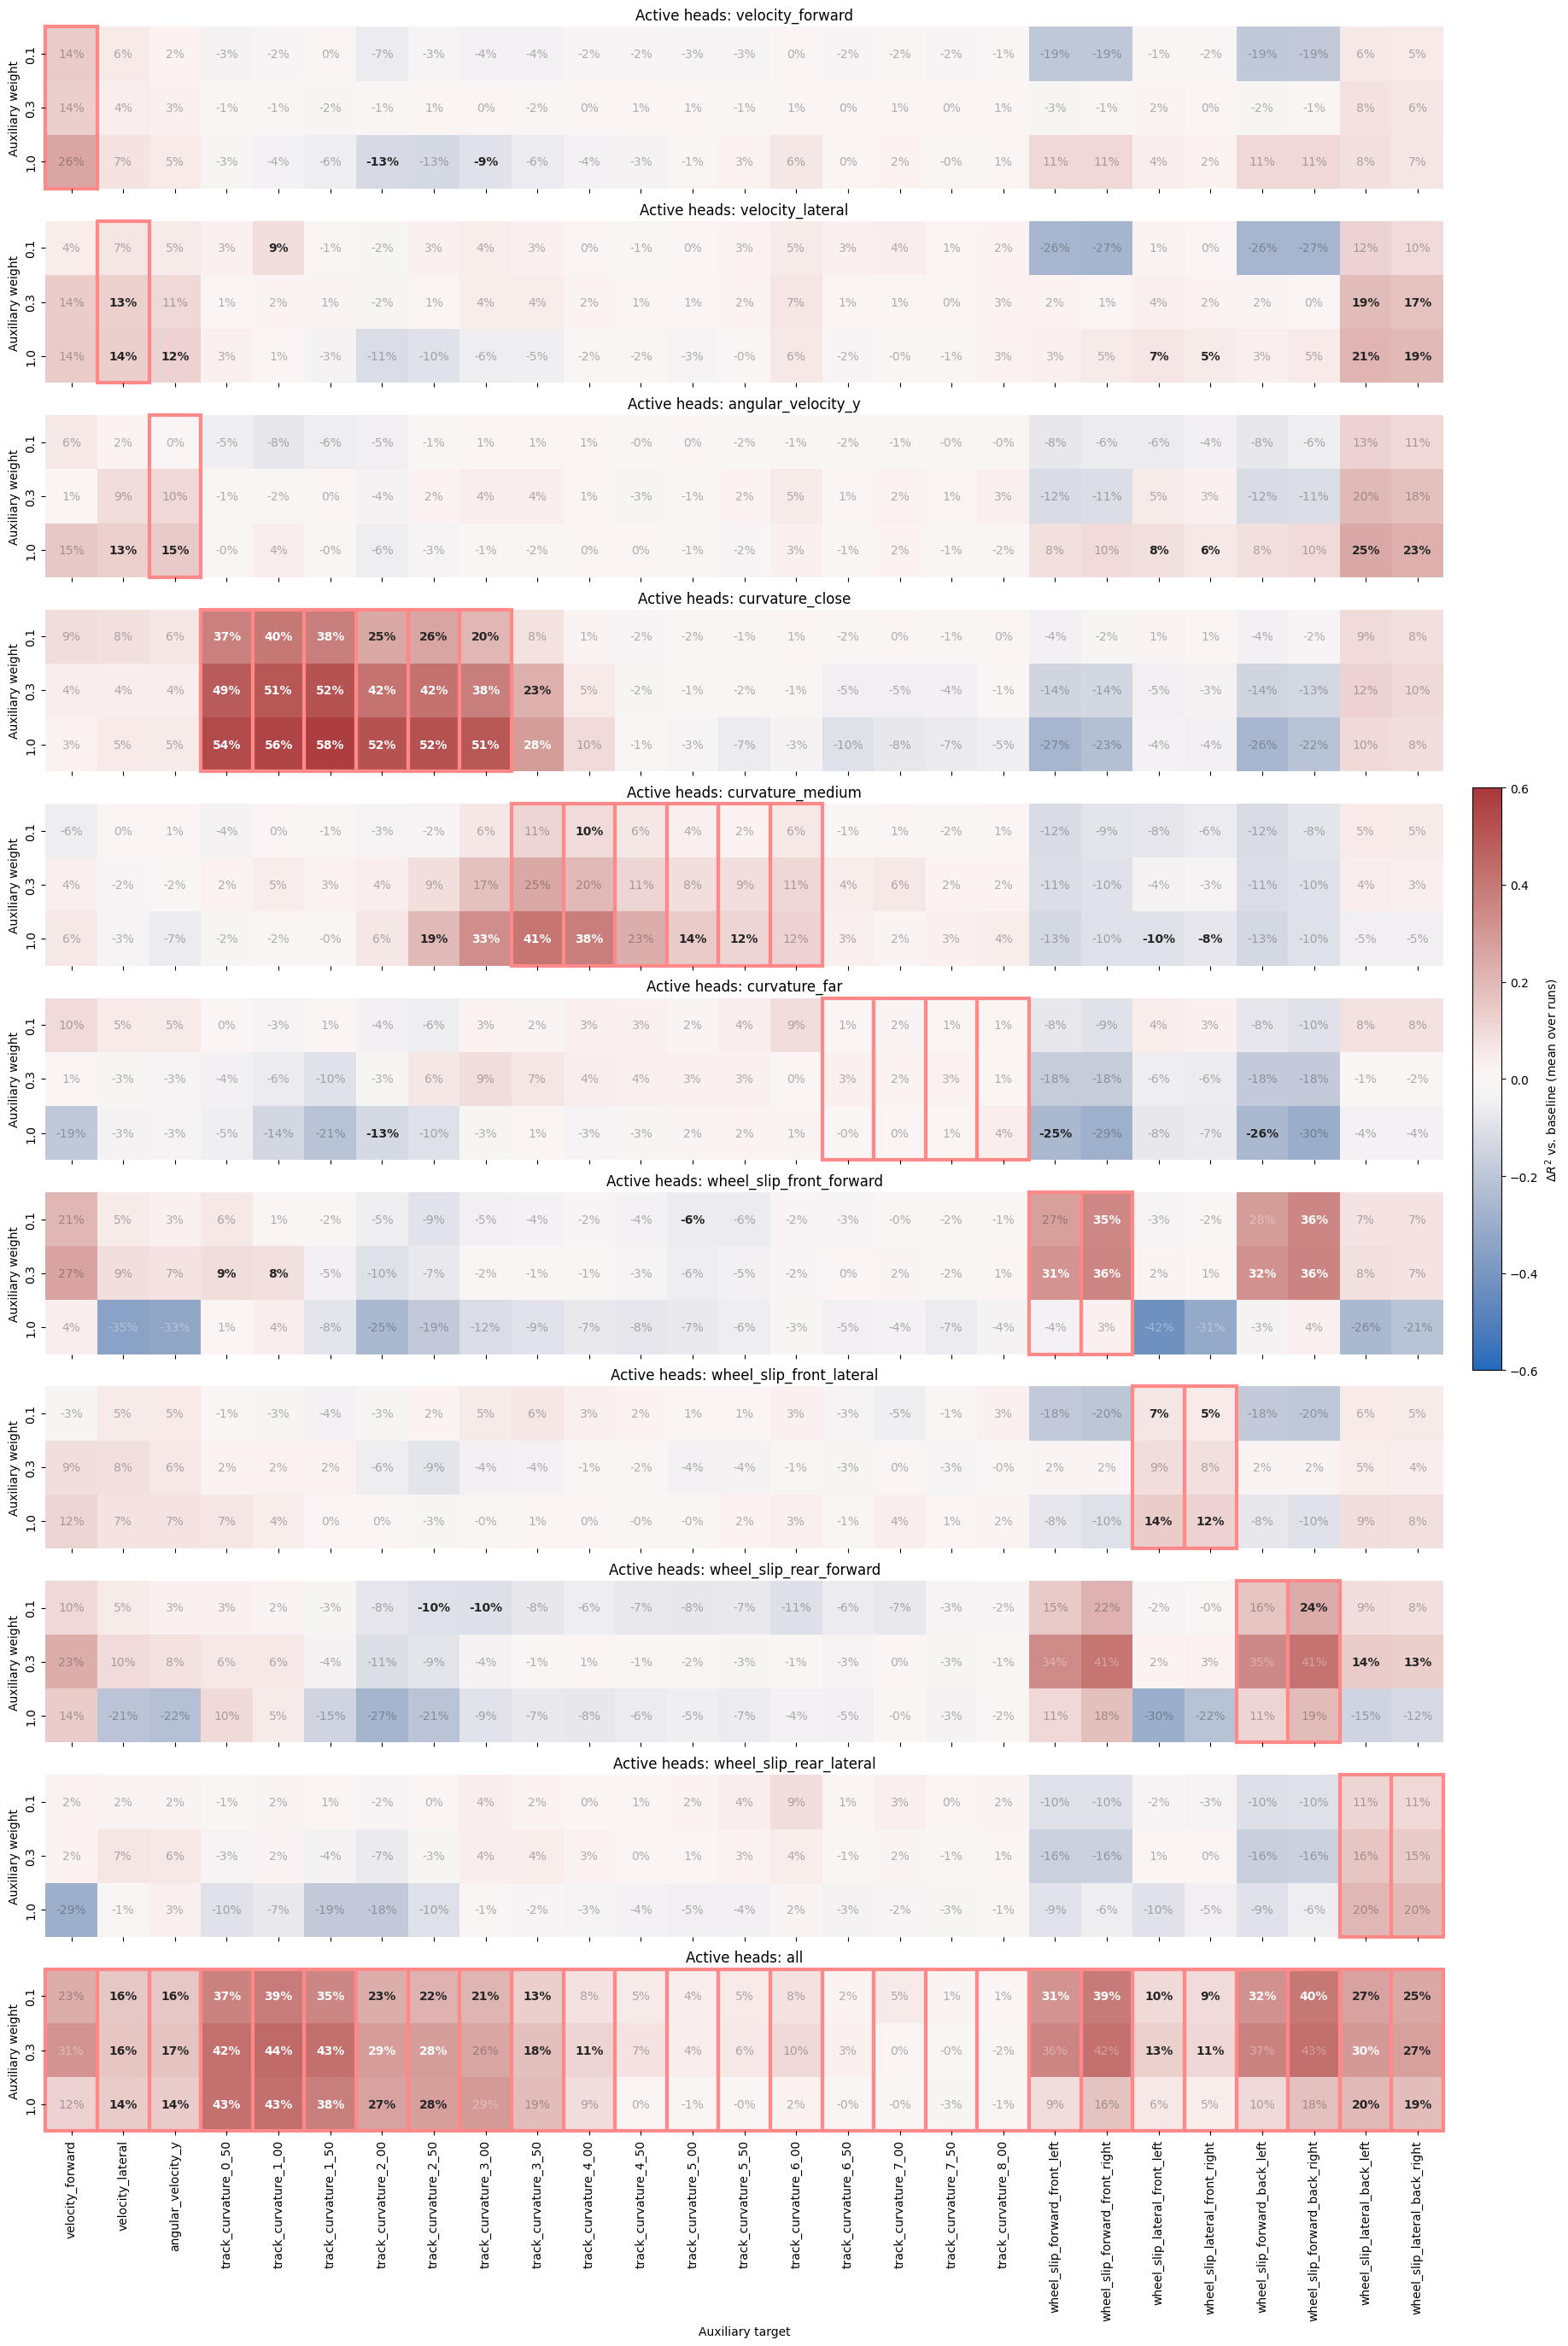

In [ ]:
last_iteration_r2_scores = data[data["iteration"] == 600].pivot(index=["model_name", "aux_weight", "run_number"], columns="target", values="r2_score")[AUX_HEAD_KEYS]
base = last_iteration_r2_scores.loc["baseline"]

last_iter_mean_r2_scores = last_iteration_r2_scores.groupby(level=["model_name", "aux_weight"]).mean()
# do Welch t-test
last_iter_ttest_results = last_iteration_r2_scores.drop("baseline").groupby(level=["model_name", "aux_weight"]).apply(
    lambda g: pd.DataFrame(ttest_ind(g, base, equal_var=False)[:2], index=["t", "p"], columns=AUX_HEAD_KEYS).T["p"]
)

# adjust for false discovery rate using Benjamini-Hochberg procedure
last_iter_ttest_results = pd.DataFrame(false_discovery_control(last_iter_ttest_results), columns=last_iter_ttest_results.columns, index=last_iter_ttest_results.index)

to_show = last_iter_mean_r2_scores.sub(last_iter_mean_r2_scores.loc["baseline"].iloc[0], axis="columns").drop("baseline")

fig, axs = plt.subplots(len(HYPERPARAMETER_GROUPS), 1, sharex="all", figsize=(22, 32))

for model, ax in zip(HYPERPARAMETER_GROUPS.keys(), axs):
    sns.heatmap(to_show.loc[model], ax=ax, annot=True, fmt=".0%", cmap="vlag", cbar=False, vmin=-0.6, vmax=0.6)

    ax.set(title=f"Active heads: {model}",
           ylabel="Auxiliary weight", xlabel="")

    for txt, is_sig in zip(ax.texts, (last_iter_ttest_results.loc[model] < 0.05).to_numpy().ravel()):
        if not is_sig:
            txt.set_alpha(0.35)
        else:
            txt.set_fontweight("bold")

    for t in HYPERPARAMETER_GROUPS[model]:
            if t in to_show.loc[model].columns:
                c = to_show.loc[model].columns.get_loc(t)
                ax.add_patch(mpatches.Rectangle((c, 0), 1, to_show.loc[model].shape[0], fill=False,
                             edgecolor="#ff8989", lw=3, clip_on=False))

axs[-1].set_xlabel("Auxiliary target")
fig.colorbar(axs[0].collections[0], ax=axs, location="right",
             label=r"$\Delta R^2$ vs. baseline (mean over runs)",
             fraction=0.02, pad=0.02)

fig.savefig("results/figures/probe_heatmap_aux.pdf", bbox_inches="tight")

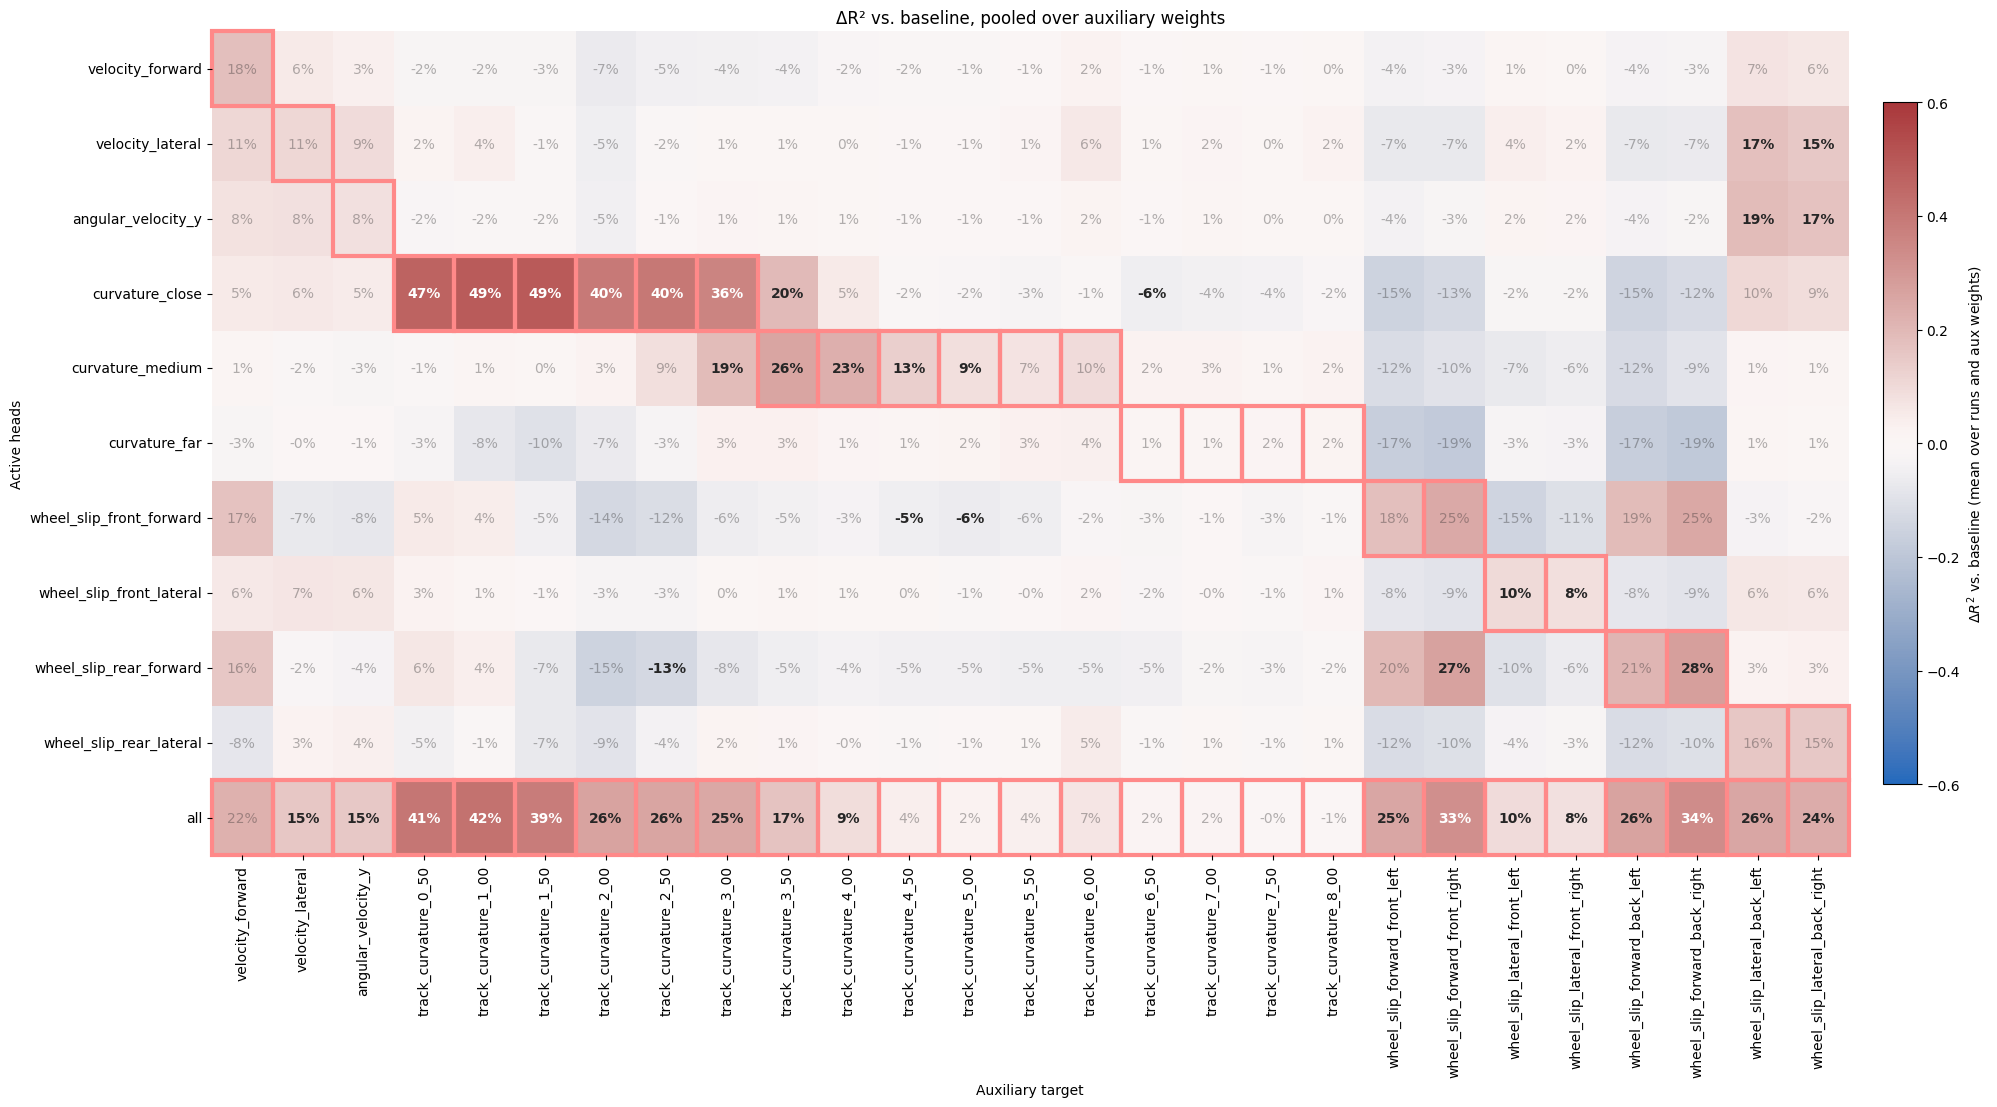

In [176]:
scores = (
    data[data["iteration"] == 600]
    .pivot(index=["model_name", "aux_weight", "run_number"], columns="target", values="r2_score")
    [AUX_HEAD_KEYS]
)
base = scores.loc["baseline"]

# pool all aux weights (and runs) per model
mean_r2 = scores.groupby(level="model_name").mean()

# Welch t-test per (model, target), all aux-weight runs pooled vs. baseline runs
pvals = scores.drop("baseline").groupby(level="model_name").apply(
    lambda g: pd.Series(ttest_ind(g, base, equal_var=False).pvalue, index=AUX_HEAD_KEYS)
)

# BH correction across the whole model x target grid
pvals = pd.DataFrame(
    false_discovery_control(pvals.to_numpy().ravel()).reshape(pvals.shape),
    index=pvals.index, columns=pvals.columns,
)

to_show = mean_r2.sub(mean_r2.loc["baseline"], axis="columns").drop("baseline")

# keep row order consistent with HYPERPARAMETER_GROUPS
row_order = [m for m in HYPERPARAMETER_GROUPS if m in to_show.index]
to_show = to_show.loc[row_order]
pvals = pvals.loc[row_order]

fig, ax = plt.subplots(figsize=(22, 0.7 * len(row_order) + 3))
sns.heatmap(to_show, ax=ax, annot=True, fmt=".0%", cmap="vlag", cbar=False, vmin=-0.6, vmax=0.6)

ax.set(title="ΔR² vs. baseline, pooled over auxiliary weights",
       xlabel="Auxiliary target", ylabel="Active heads")

# fade non-significant cells, bold significant ones (position-based, so NaN cells can't misalign)
sig = (pvals < 0.05).to_numpy()
for txt in ax.texts:
    x, y = txt.get_position()
    if sig[int(y), int(x)]:
        txt.set_fontweight("bold")
    else:
        txt.set_alpha(0.35)

# outline the cells for each model's active heads
for r, model in enumerate(row_order):
    for t in HYPERPARAMETER_GROUPS[model]:
        if t in to_show.columns:
            c = to_show.columns.get_loc(t)
            ax.add_patch(mpatches.Rectangle((c, r), 1, 1, fill=False,
                                            edgecolor="#ff8989", lw=3, clip_on=False))

fig.colorbar(ax.collections[0], ax=ax, location="right",
             label=r"$\Delta R^2$ vs. baseline (mean over runs and aux weights)",
             fraction=0.02, pad=0.02)

fig.savefig("results/figures/probe_heatmap_aux_pooled.pdf", bbox_inches="tight")

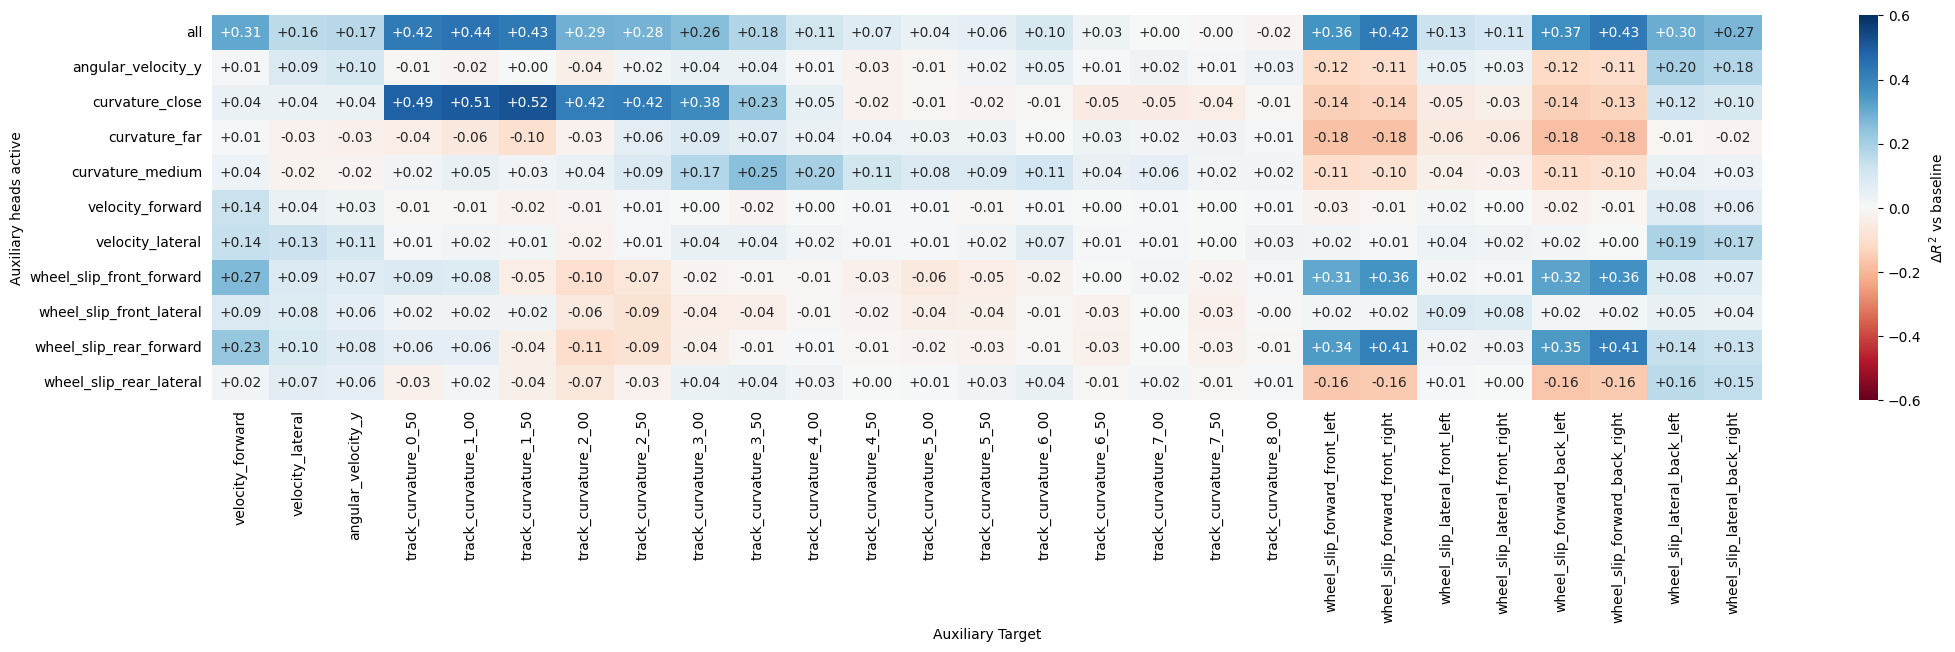

In [10]:
aux_weight = 0.3

pivot = (
    data[((data["aux_weight"] == aux_weight) | (data["model_name"] == "baseline"))
         & (data["iteration"] == 600)]
    .groupby(["model_name", "target"])["r2_score"]
    .mean()
    .unstack("target")
    .reindex(columns=AUX_HEAD_KEYS)
)

delta = pivot.sub(pivot.loc["baseline"], axis="columns").drop(index="baseline")

plt.figure(figsize=(25, 5))
heatmap = sns.heatmap(
    delta,
    cmap="RdBu",
    center=0,
    vmin=-0.6, vmax=0.6,
    cbar_kws={"label": r"$\Delta R^2$ vs baseline"},
    annot=True,
    fmt="+.2f"
)


heatmap.tick_params(left=False, bottom=False)
heatmap.set(xlabel="Auxiliary Target", ylabel="Auxiliary heads active")
plt.savefig("results/figures/probe_heatmap_delta_vs_baseline.pdf", bbox_inches='tight')


In [11]:
pivot.sub(pivot.loc["baseline"]).loc["curvature_close"]

target
velocity_forward                  0.039738
velocity_lateral                  0.039592
angular_velocity_y                0.039607
track_curvature_0_50              0.492163
track_curvature_1_00              0.505046
track_curvature_1_50              0.516620
track_curvature_2_00              0.415006
track_curvature_2_50              0.420845
track_curvature_3_00              0.380468
track_curvature_3_50              0.225736
track_curvature_4_00              0.051721
track_curvature_4_50             -0.023786
track_curvature_5_00             -0.011826
track_curvature_5_50             -0.015611
track_curvature_6_00             -0.007504
track_curvature_6_50             -0.051366
track_curvature_7_00             -0.051103
track_curvature_7_50             -0.044816
track_curvature_8_00             -0.008940
wheel_slip_forward_front_left    -0.143720
wheel_slip_forward_front_right   -0.139025
wheel_slip_lateral_front_left    -0.046889
wheel_slip_lateral_front_right   -0.034140
whee